# ICS 471 Deep Learning – Milestone 3: CNNs and Transfer Learning

**Team:** Abdulaziz Alguraini (202255320), Bader Alqahatani (202274680)
**Section:** 01
**Dataset:** Arabic Handwritten Characters Dataset (AHCD)

In this milestone we move from MLPs to convolutional networks. In **Part 1** we design and train a CNN from scratch, tune it, train it with early stopping, and save the selected checkpoint. In **Part 2** we use three ImageNet-pretrained networks (VGG19, ResNet18 and MobileNetV2) with three transfer learning strategies, save the best one, and use it as a feature extractor for classical machine learning models.

We keep exactly the same data split as in Milestone 2. Augmentation is only applied to the training images. All choices (hyperparameters, checkpoints, learning rates, models) are made on the validation set, and the test set is only used after a choice is fixed.

## 0. Setup

In [33]:
import glob
import json
import os
import random
import shutil
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display
from matplotlib.patches import FancyBboxPatch
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

SEED = 42
DATA_DIR = "data"
CKPT_DIR = "checkpoints"
LOG_DIR = "logs"
IMAGE_SIZE = 32
BATCH_SIZE = 128
LOSS_NAME = "CE + Label Smoothing"
NUM_WORKERS = 0 if os.name == "nt" else 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for folder in (CKPT_DIR, LOG_DIR):
    os.makedirs(folder, exist_ok=True)

LETTERS = [
    "alef", "beh", "teh", "theh", "jeem", "hah", "khah", "dal", "thal", "reh",
    "zain", "seen", "sheen", "sad", "dad", "tah", "zah", "ain", "ghain", "feh",
    "qaf", "kaf", "lam", "meem", "noon", "heh", "waw", "yeh",
]

pd.set_option("display.precision", 4)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Device:", DEVICE, f"({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else "")

PyTorch: 2.14.1+cu130 | torchvision: 0.29.1+cu130
Device: cuda (Tesla T4)


## 1. Data (same split as Milestone 2)

These functions are copied from Milestone 2 without changes, so the training, validation and test sets are exactly the same: the official AHCD test set is kept as the test set, and the official training set is split 80/20 into training and validation, stratified by class with seed 42.

In [34]:
def find_csv(data_dir, *keywords):
    paths = glob.glob(os.path.join(data_dir, "**", "*.csv"), recursive=True)
    matches = [p for p in paths if all(k in os.path.basename(p).lower() for k in keywords)]
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected one CSV matching {keywords} in '{data_dir}', found: {matches}")
    return matches[0]


def load_ahcd(data_dir=DATA_DIR):
    def read(*keywords):
        return pd.read_csv(find_csv(data_dir, *keywords), header=None).values

    X_train = read("train", "image").astype(np.float32)
    y_train = read("train", "label").ravel()
    X_test = read("test", "image").astype(np.float32)
    y_test = read("test", "label").ravel()
    return X_train, y_train, X_test, y_test


def to_images(X, size=IMAGE_SIZE, transpose=True):
    images = X.reshape(-1, size, size)
    return images.transpose(0, 2, 1) if transpose else images


def split_data(X, y, X_test=None, y_test=None, test_size=0.2, val_size=0.2, seed=SEED):
    if X_test is None or y_test is None:
        X, X_test, y, y_test = train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed)
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=val_size, stratify=y, random_state=seed)
    return X_train, y_train, X_val, y_val, X_test, y_test


class Preprocessor:
    def __init__(self, size=IMAGE_SIZE, transpose=True):
        self.size = size
        self.transpose = transpose
        self.mean = None
        self.std = None
        self.encoder = LabelEncoder()

    def fit(self, X, y):
        pixels = X.astype(np.float32) / 255.0
        self.mean = float(pixels.mean())
        self.std = float(pixels.std())
        self.encoder.fit(y)
        return self

    def transform(self, X, y):
        images = to_images(X, self.size, self.transpose).astype(np.float32) / 255.0
        images = (images - self.mean) / self.std
        features = images.reshape(len(images), -1)
        labels = self.encoder.transform(y)
        return torch.tensor(features, dtype=torch.float32), torch.tensor(labels, dtype=torch.long)

In [35]:
X_full, y_full, X_test_raw, y_test_raw = load_ahcd()
X_train_raw, y_train_raw, X_val_raw, y_val_raw, X_test_raw, y_test_raw = split_data(X_full, y_full, X_test_raw, y_test_raw)
prep = Preprocessor().fit(X_train_raw, y_train_raw)
NUM_CLASSES = len(prep.encoder.classes_)

display(pd.DataFrame({
    "split": ["train", "validation", "test"],
    "images": [len(y_train_raw), len(y_val_raw), len(y_test_raw)],
    "images per class": [pd.Series(s).value_counts().min() for s in (y_train_raw, y_val_raw, y_test_raw)],
}))
print("Classes:", NUM_CLASSES)

,split,images,images per class
0,train,10752,384
1,validation,2688,96
2,test,3360,120


Classes: 28


# Part 1: CNN Trained from Scratch

### 1.1 Preprocessing

For the CNN we keep the images in their 2D shape (1 × 32 × 32) instead of flattening them like we did for the MLP, because the convolution layers need the spatial structure.

1. **Reshaping and orientation.** Each CSV row is reshaped to 32 × 32 and transposed so the letter is upright (same as Milestone 2).
2. **Scaling.** Pixels are divided by 255 so they are in [0, 1].
3. **Mean subtraction and scaling.** We subtract the mean pixel value of the training images and divide by their standard deviation. These two numbers come from the training split only and are reused for validation and test.
4. **Label encoding.** Labels 1–28 are mapped to 0–27 with the `LabelEncoder` fitted on the training labels.

Augmentation (next section) is applied to the [0, 1] image *before* the mean subtraction, so the background stays black when an image is rotated or shifted.

In [36]:
def to_image_tensor(X):
    return torch.tensor(to_images(X) / 255.0, dtype=torch.float32).unsqueeze(1)


def to_label_tensor(y):
    return torch.tensor(prep.encoder.transform(y), dtype=torch.long)


train_images, val_images, test_images = (to_image_tensor(X) for X in (X_train_raw, X_val_raw, X_test_raw))
train_labels, val_labels, test_labels = (to_label_tensor(y) for y in (y_train_raw, y_val_raw, y_test_raw))
TRAIN_MEAN, TRAIN_STD = prep.mean, prep.std


class AHCDDataset(Dataset):
    def __init__(self, images, labels, transform=None, mean=None, std=None):
        self.images = images
        self.labels = labels
        self.transform = transform
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        x = self.images[idx]
        if self.transform is not None:
            x = self.transform(x)
        if self.mean is not None:
            x = (x - self.mean) / self.std
        return x, self.labels[idx]


def make_loaders(train_transform=None, mean=None, std=None, batch_size=BATCH_SIZE):
    pin = torch.cuda.is_available()
    train_ds = AHCDDataset(train_images, train_labels, train_transform, mean, std)
    val_ds = AHCDDataset(val_images, val_labels, None, mean, std)
    test_ds = AHCDDataset(test_images, test_labels, None, mean, std)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=True,
                              num_workers=NUM_WORKERS, pin_memory=pin)
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
    test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
    return train_loader, val_loader, test_loader


print("Image tensor shapes:", tuple(train_images.shape), tuple(val_images.shape), tuple(test_images.shape))
print(f"Training mean / std used for mean subtraction: {TRAIN_MEAN:.4f} / {TRAIN_STD:.4f}")
xb, _ = AHCDDataset(train_images, train_labels, None, TRAIN_MEAN, TRAIN_STD)[0]
print(f"One preprocessed image: shape {tuple(xb.shape)}, min {xb.min():.3f}, max {xb.max():.3f}")

Image tensor shapes: (10752, 1, 32, 32) (2688, 1, 32, 32) (3360, 1, 32, 32)
Training mean / std used for mean subtraction: 0.0528 / 0.1945
One preprocessed image: shape (1, 32, 32), min -0.271, max 4.870


### 1.2 Data augmentation

We use three label-preserving augmentations that match how people actually write:

- **Small rotation (±10°):** handwriting is often slightly tilted.
- **Small shift (up to 10% in each direction):** letters are not always centered in the 32 × 32 frame.
- **Small zoom (90–110%):** people write letters at different sizes.

We do **not** use flips. A mirrored Arabic letter is not a valid letter, and some flips would move the dots to the wrong side. We also keep the rotation small so that letters do not start to look like other letters. A new random version of every training image is created each epoch, and validation and test images are never augmented.

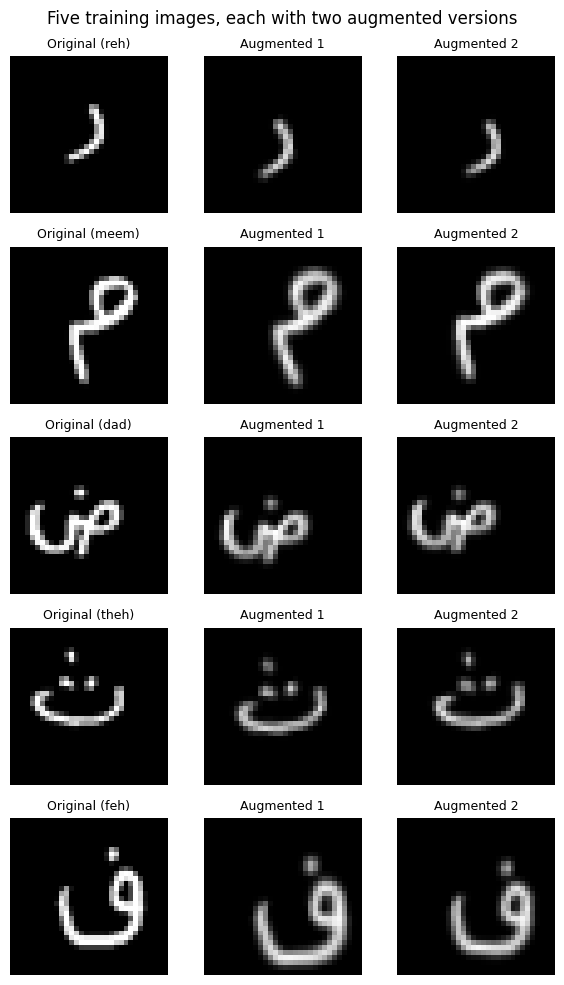

In [37]:
train_transform = transforms.Compose([
    transforms.RandomRotation(10, interpolation=transforms.InterpolationMode.BILINEAR, fill=0),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1),
                            interpolation=transforms.InterpolationMode.BILINEAR, fill=0),
])


def show_augmentations(images, labels, transform, n=5, seed=SEED):
    set_seed(seed)
    idx = np.random.default_rng(seed).choice(len(labels), n, replace=False)
    fig, axes = plt.subplots(n, 3, figsize=(6, 2 * n))
    for row, i in enumerate(idx):
        original = images[i]
        versions = [original, transform(original), transform(original)]
        titles = [f"Original ({LETTERS[int(labels[i])]})", "Augmented 1", "Augmented 2"]
        for col in range(3):
            axes[row, col].imshow(versions[col].squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
            axes[row, col].set_title(titles[col], fontsize=9)
            axes[row, col].axis("off")
    fig.suptitle("Five training images, each with two augmented versions", fontsize=12)
    plt.tight_layout()
    plt.show()


show_augmentations(train_images, train_labels, train_transform)

### 1.3 CNN model

Our CNN has **six convolutional layers** in three blocks. Each block has two 3 × 3 convolutions (each followed by batch normalization and ReLU) and then a 2 × 2 max-pooling layer that halves the image size (32 → 16 → 8 → 4). The number of filters doubles in every block (32 → 64 → 128), so the network learns more complex shapes as the image gets smaller.

The classifier head flattens the 128 × 4 × 4 feature map and uses one hidden fully connected layer with 256 units, ReLU and dropout, followed by a linear output layer with 28 units (one logit per letter; the softmax is inside the loss function). We flatten instead of using global average pooling because the *position* of the dots matters in Arabic (for example beh and noon), and flattening keeps that information.

AHCDCNN(
  (block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (b

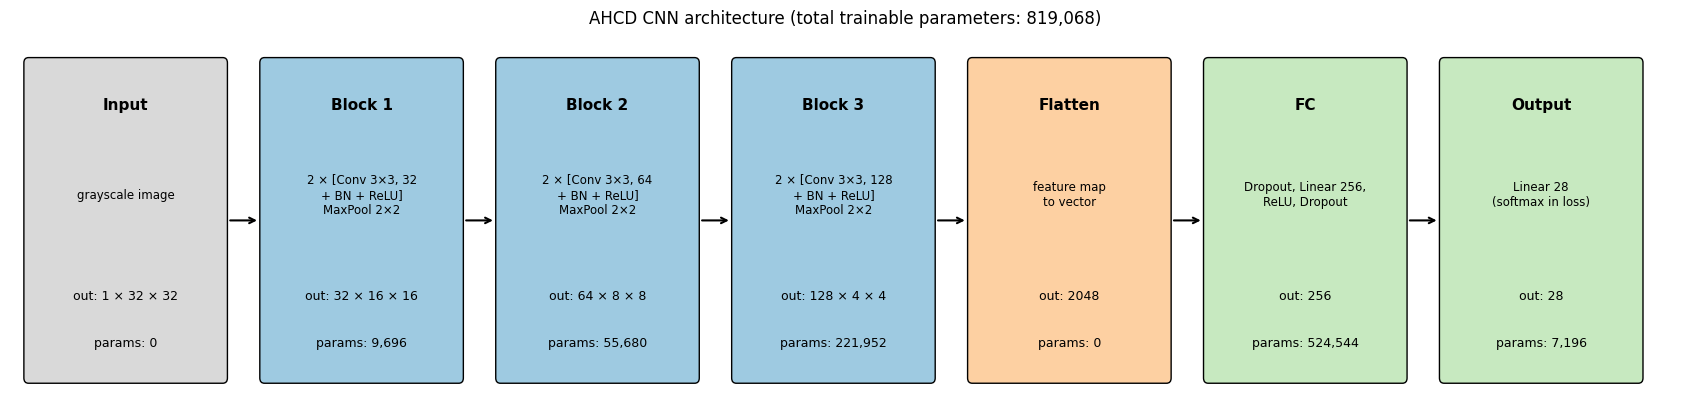

,layer,type,output shape,trainable params
0,block1.0,Conv2d,32 × 32 × 32,320
1,block1.1,BatchNorm2d,32 × 32 × 32,64
2,block1.2,ReLU,32 × 32 × 32,0
3,block1.3,Conv2d,32 × 32 × 32,9248
4,block1.4,BatchNorm2d,32 × 32 × 32,64
5,block1.5,ReLU,32 × 32 × 32,0
6,block1.6,MaxPool2d,32 × 16 × 16,0
7,block2.0,Conv2d,64 × 16 × 16,18496
8,block2.1,BatchNorm2d,64 × 16 × 16,128
9,block2.2,ReLU,64 × 16 × 16,0


Total trainable parameters: 819,068


In [38]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class AHCDCNN(nn.Module):
    def __init__(self, base_filters=32, dropout=0.3, num_classes=NUM_CLASSES):
        super().__init__()
        f = base_filters
        self.base_filters = f
        self.block1 = conv_block(1, f)
        self.block2 = conv_block(f, 2 * f)
        self.block3 = conv_block(2 * f, 4 * f)
        self.flatten = nn.Flatten()
        self.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(4 * f * 4 * 4, 256), nn.ReLU(), nn.Dropout(dropout))
        self.out = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.block3(self.block2(self.block1(x)))
        return self.out(self.fc(self.flatten(x)))


def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total


def layer_summary(model, input_shape=(1, 1, IMAGE_SIZE, IMAGE_SIZE)):
    rows, hooks = [], []
    for name, module in model.named_modules():
        if len(list(module.children())) == 0:
            hooks.append(module.register_forward_hook(
                lambda m, inp, out, name=name: rows.append({
                    "layer": name,
                    "type": type(m).__name__,
                    "output shape": " × ".join(str(d) for d in out.shape[1:]),
                    "trainable params": sum(p.numel() for p in m.parameters() if p.requires_grad),
                })))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_shape, device=next(model.parameters()).device))
    for h in hooks:
        h.remove()
    return pd.DataFrame(rows)


def draw_architecture(model):
    f = model.base_filters
    stages = [
        ("Input", None, "grayscale image"),
        ("Block 1", model.block1, f"2 × [Conv 3×3, {f}\n+ BN + ReLU]\nMaxPool 2×2"),
        ("Block 2", model.block2, f"2 × [Conv 3×3, {2 * f}\n+ BN + ReLU]\nMaxPool 2×2"),
        ("Block 3", model.block3, f"2 × [Conv 3×3, {4 * f}\n+ BN + ReLU]\nMaxPool 2×2"),
        ("Flatten", model.flatten, "feature map\nto vector"),
        ("FC", model.fc, "Dropout, Linear 256,\nReLU, Dropout"),
        ("Output", model.out, "Linear 28\n(softmax in loss)"),
    ]
    shapes, hooks = {}, []
    for name, module, _ in stages:
        if module is not None:
            hooks.append(module.register_forward_hook(
                lambda m, inp, out, name=name: shapes.__setitem__(name, tuple(out.shape[1:]))))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 1, IMAGE_SIZE, IMAGE_SIZE, device=next(model.parameters()).device))
    for h in hooks:
        h.remove()
    shapes["Input"] = (1, IMAGE_SIZE, IMAGE_SIZE)

    fig, ax = plt.subplots(figsize=(17, 4.2))
    width, gap = 2.1, 0.45
    colors = ["#d9d9d9", "#9ecae1", "#9ecae1", "#9ecae1", "#fdd0a2", "#c7e9c0", "#c7e9c0"]
    for i, (name, module, detail) in enumerate(stages):
        x = i * (width + gap)
        params = 0 if module is None else sum(p.numel() for p in module.parameters() if p.requires_grad)
        ax.add_patch(FancyBboxPatch((x, 0), width, 3, boxstyle="round,pad=0.05", facecolor=colors[i], edgecolor="black"))
        ax.text(x + width / 2, 2.6, name, ha="center", va="center", fontsize=11, fontweight="bold")
        ax.text(x + width / 2, 1.75, detail, ha="center", va="center", fontsize=8.5)
        ax.text(x + width / 2, 0.75, "out: " + " × ".join(str(d) for d in shapes[name]), ha="center", fontsize=9)
        ax.text(x + width / 2, 0.3, f"params: {params:,}", ha="center", fontsize=9)
        if i < len(stages) - 1:
            ax.annotate("", xy=(x + width + gap - 0.05, 1.5), xytext=(x + width + 0.05, 1.5),
                        arrowprops=dict(arrowstyle="->", lw=1.5))
    trainable, _ = count_params(model)
    ax.set_title(f"AHCD CNN architecture (total trainable parameters: {trainable:,})", fontsize=12)
    ax.set_xlim(-0.2, len(stages) * (width + gap))
    ax.set_ylim(-0.2, 3.3)
    ax.axis("off")
    plt.tight_layout()
    plt.show()


example_cnn = AHCDCNN().to(DEVICE)
print(example_cnn)
draw_architecture(example_cnn)
summary_df = layer_summary(example_cnn)
display(summary_df)
print(f"Total trainable parameters: {count_params(example_cnn)[0]:,}")

### Training methods

These methods are shared by every model in this notebook (CNN, MLP and the pretrained networks).

- `run_epoch` trains or evaluates for one epoch. When some layers are frozen, it also keeps their batch normalization layers in evaluation mode, so the frozen statistics do not change.
- `EarlyStopping` watches one metric. It saves a checkpoint every time the metric improves and stops training after `patience` epochs without improvement.
- `fit` trains a model, writes a CSV log with one row per epoch, and returns the model with the weights selected on the validation set (or by early stopping).

In [39]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction="none")
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


def get_loss(name):
    if name == "CrossEntropy":
        return nn.CrossEntropyLoss()
    if name == "CE + Label Smoothing":
        return nn.CrossEntropyLoss(label_smoothing=0.1)
    if name == "Focal":
        return FocalLoss(gamma=2.0)
    raise ValueError(f"Unknown loss: {name}")


def get_optimizer(name, params, lr, weight_decay=1e-4):
    if name == "SGD":
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == "RMSprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    if name == "Adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(f"Unknown optimizer: {name}")


def freeze_batchnorm(model):
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training:
        freeze_batchnorm(model)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            count += len(yb)
    return total_loss / count, correct / count


class EarlyStopping:
    def __init__(self, monitor="val_acc", patience=5, min_delta=0.0, checkpoint_path="checkpoint.pt"):
        self.monitor = monitor
        self.mode = "min" if "loss" in monitor else "max"
        self.patience = patience
        self.min_delta = min_delta
        self.checkpoint_path = checkpoint_path
        self.best = None
        self.best_epoch = 0
        self.counter = 0

    def step(self, epoch, metrics, model):
        value = metrics[self.monitor]
        if self.mode == "min":
            improved = self.best is None or value < self.best - self.min_delta
        else:
            improved = self.best is None or value > self.best + self.min_delta
        if improved:
            self.best, self.best_epoch, self.counter = value, epoch, 0
            torch.save(model.state_dict(), self.checkpoint_path)
        else:
            self.counter += 1
        return self.counter >= self.patience


def fit(model, train_loader, val_loader, epochs, lr, weight_decay=1e-4, optimizer_name="Adam",
        loss_name=LOSS_NAME, early_stopping=None, log_name=None, verbose=False):
    criterion = get_loss(loss_name)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = get_optimizer(optimizer_name, params, lr, weight_decay)
    history, best_acc, best_epoch, best_state = [], -1.0, 0, None
    start = time.time()
    for epoch in range(1, epochs + 1):
        epoch_start = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        row = {"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
               "val_loss": val_loss, "val_acc": val_acc, "seconds": time.time() - epoch_start}
        history.append(row)
        if verbose:
            print(f"epoch {epoch:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} "
                  f"| val loss {val_loss:.4f} acc {val_acc:.4f}")
        if early_stopping is not None:
            if early_stopping.step(epoch, row, model):
                if verbose:
                    print(f"Early stopping at epoch {epoch}: no improvement in {early_stopping.monitor} "
                          f"for {early_stopping.patience} epochs")
                break
        elif val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    history = pd.DataFrame(history)
    if log_name is not None:
        history.to_csv(os.path.join(LOG_DIR, f"{log_name}.csv"), index=False)
    if early_stopping is not None:
        model.load_state_dict(torch.load(early_stopping.checkpoint_path, map_location=DEVICE))
        best_epoch = early_stopping.best_epoch
    else:
        model.load_state_dict(best_state)
    selected = history.loc[history["epoch"] == best_epoch].iloc[0]
    info = {"selected epoch": int(best_epoch), "epochs run": len(history),
            "train acc": selected["train_acc"], "val acc": selected["val_acc"], "val loss": selected["val_loss"],
            "time (s)": time.time() - start}
    return history, info


@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, targets = [], []
    for xb, yb in loader:
        preds.append(model(xb.to(DEVICE)).argmax(dim=1).cpu())
        targets.append(yb)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()


def evaluate(model, loader, loss_name=LOSS_NAME):
    loss, acc = run_epoch(model, loader, get_loss(loss_name))
    preds, targets = predict(model, loader)
    return {"test loss": loss, "test acc": acc, "test macro F1": f1_score(targets, preds, average="macro")}

### 1.4 Hyperparameter tuning

We train the CNN with four settings and vary three hyperparameters: the **learning rate**, the **dropout probability** and the **number of filters** in the first block (the other blocks scale with it). Every setting uses Adam, weight decay 1e-4, batch size 128, augmentation, and the same seed, and is trained for 15 epochs. For the loss we use cross-entropy with label smoothing (0.1), because it gave the best validation accuracy in our Milestone 2 comparison of loss functions. For each setting we record the best validation accuracy.

In [40]:
cnn_train_loader, cnn_val_loader, cnn_test_loader = make_loaders(train_transform, TRAIN_MEAN, TRAIN_STD)

TUNE_EPOCHS = 15
CNN_SETTINGS = [
    {"lr": 1e-3, "dropout": 0.3, "base_filters": 32},
    {"lr": 1e-3, "dropout": 0.5, "base_filters": 32},
    {"lr": 3e-4, "dropout": 0.3, "base_filters": 32},
    {"lr": 1e-3, "dropout": 0.3, "base_filters": 64},
]

tune_rows = []
for i, setting in enumerate(CNN_SETTINGS, start=1):
    set_seed()
    model = AHCDCNN(setting["base_filters"], setting["dropout"]).to(DEVICE)
    _, info = fit(model, cnn_train_loader, cnn_val_loader, TUNE_EPOCHS, setting["lr"], log_name=f"cnn_tuning_setting{i}")
    tune_rows.append({"setting": i, **setting, "trainable params": count_params(model)[0],
                      "best val acc": info["val acc"], "best epoch": info["selected epoch"], "time (s)": info["time (s)"]})
    print(f"Setting {i} {setting}: best val acc {info['val acc']:.4f} (epoch {info['selected epoch']})")

tune_df = pd.DataFrame(tune_rows)
display(tune_df)
best_setting = CNN_SETTINGS[int(tune_df["best val acc"].idxmax())]
print("Best setting:", best_setting)

Setting 1 {'lr': 0.001, 'dropout': 0.3, 'base_filters': 32}: best val acc 0.9788 (epoch 14)
Setting 2 {'lr': 0.001, 'dropout': 0.5, 'base_filters': 32}: best val acc 0.9706 (epoch 12)
Setting 3 {'lr': 0.0003, 'dropout': 0.3, 'base_filters': 32}: best val acc 0.9762 (epoch 14)
Setting 4 {'lr': 0.001, 'dropout': 0.3, 'base_filters': 64}: best val acc 0.9736 (epoch 15)


,setting,lr,dropout,base_filters,trainable params,best val acc,best epoch,time (s)
0,1,0.0010,0.3,32,819068,0.9788,14,137.7374
1,2,0.0010,0.5,32,819068,0.9706,12,140.5999
2,3,0.0003,0.3,32,819068,0.9762,14,139.7196
3,4,0.0010,0.3,64,2202076,0.9736,15,145.8532


Best setting: {'lr': 0.001, 'dropout': 0.3, 'base_filters': 32}


**Discussion.** All four settings reach about 97–98% validation accuracy, so the CNN is not very sensitive to these hyperparameters. Setting 1 (learning rate 0.001, dropout 0.3, 32 filters) is the best with 0.9788.

- Raising the dropout to 0.5 gave the lowest score (0.9706). With augmentation and batch normalization the network already has enough regularization, so the extra dropout mostly slows learning down.
- The smaller learning rate (0.0003) was close (0.9762), but it learns more slowly and would probably need more than 15 epochs to catch up.
- Doubling the filters to 64 almost triples the number of parameters (2.2 million instead of 0.82 million) and did not improve the result (0.9736), so we keep the smaller network.

### 1.5 Early stopping

Using the best setting, we train the CNN three more times with early stopping (patience 5, at most 40 epochs). Each run watches a different metric:

- **Training accuracy:** stop when the model stops improving on the training data.
- **Validation accuracy:** stop when the model stops improving on unseen data.
- **Validation loss:** stop when the validation loss stops decreasing.

Each run keeps the checkpoint from the epoch where its metric was best. We compare these checkpoints on the validation set, select the best one, and only then evaluate it on the test set.

In [41]:
MAX_EPOCHS = 40
PATIENCE = 5
MONITORS = {"train_acc": "Training accuracy", "val_acc": "Validation accuracy", "val_loss": "Validation loss"}

es_rows, es_histories = [], {}
for monitor, label in MONITORS.items():
    print(f"--- Early stopping on {label} ---")
    set_seed()
    model = AHCDCNN(best_setting["base_filters"], best_setting["dropout"]).to(DEVICE)
    stopper = EarlyStopping(monitor, patience=PATIENCE, checkpoint_path=os.path.join(CKPT_DIR, f"cnn_es_{monitor}.pt"))
    history, info = fit(model, cnn_train_loader, cnn_val_loader, MAX_EPOCHS, best_setting["lr"],
                        early_stopping=stopper, log_name=f"cnn_early_stopping_{monitor}", verbose=True)
    es_histories[monitor] = history
    es_rows.append({"monitored metric": label, "monitor": monitor, **info})
    print()

es_df = pd.DataFrame(es_rows)
display(es_df.drop(columns="monitor"))

--- Early stopping on Training accuracy ---
epoch  1 | train loss 2.3069 acc 0.3710 | val loss 1.4965 acc 0.6815
epoch  2 | train loss 1.3050 acc 0.7927 | val loss 1.0418 acc 0.9066
epoch  3 | train loss 1.0804 acc 0.8947 | val loss 0.9329 acc 0.9379
epoch  4 | train loss 0.9918 acc 0.9239 | val loss 1.0121 acc 0.8951
epoch  5 | train loss 0.9478 acc 0.9359 | val loss 1.2863 acc 0.7612
epoch  6 | train loss 0.9132 acc 0.9475 | val loss 0.8238 acc 0.9647
epoch  7 | train loss 0.8931 acc 0.9523 | val loss 0.8014 acc 0.9743
epoch  8 | train loss 0.8737 acc 0.9582 | val loss 0.8282 acc 0.9572
epoch  9 | train loss 0.8602 acc 0.9614 | val loss 0.9124 acc 0.9048
epoch 10 | train loss 0.8466 acc 0.9658 | val loss 0.8031 acc 0.9606
epoch 11 | train loss 0.8373 acc 0.9667 | val loss 0.8192 acc 0.9505
epoch 12 | train loss 0.8321 acc 0.9701 | val loss 0.8405 acc 0.9494
epoch 13 | train loss 0.8148 acc 0.9746 | val loss 0.7855 acc 0.9673
epoch 14 | train loss 0.8100 acc 0.9746 | val loss 0.7518 a

,monitored metric,selected epoch,epochs run,train acc,val acc,val loss,time (s)
0,Training accuracy,40,40,0.9897,0.9829,0.7129,372.3451
1,Validation accuracy,7,12,0.9531,0.9728,0.8041,110.5929
2,Validation loss,25,30,0.9827,0.9803,0.7218,276.7909


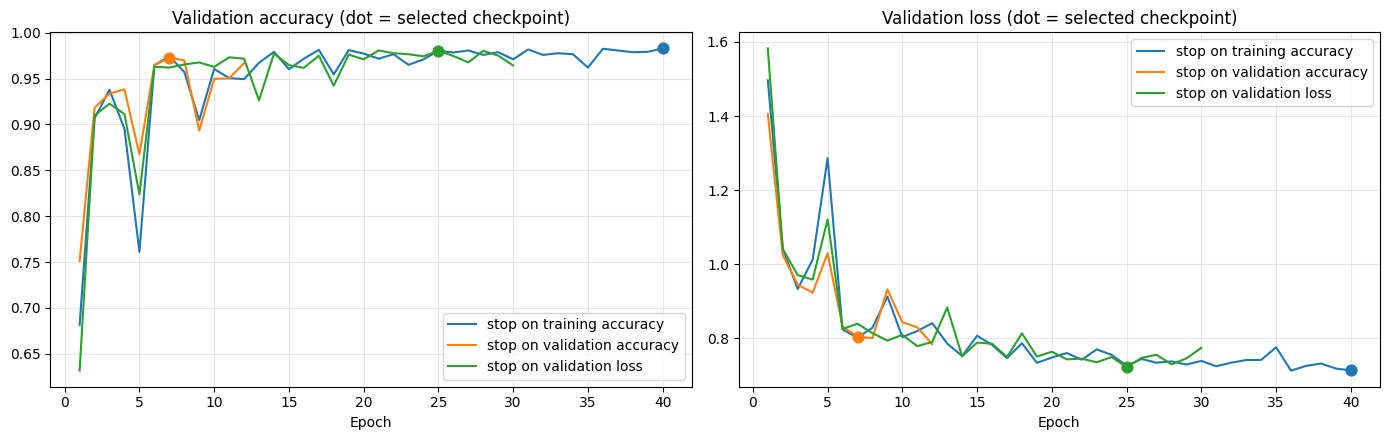

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (monitor, label), color in zip(MONITORS.items(), ["tab:blue", "tab:orange", "tab:green"]):
    h = es_histories[monitor]
    sel = int(es_df.loc[es_df["monitor"] == monitor, "selected epoch"].iloc[0])
    axes[0].plot(h["epoch"], h["val_acc"], color=color, label=f"stop on {label.lower()}")
    axes[0].scatter(sel, h.loc[h["epoch"] == sel, "val_acc"], color=color, s=60, zorder=3)
    axes[1].plot(h["epoch"], h["val_loss"], color=color, label=f"stop on {label.lower()}")
    axes[1].scatter(sel, h.loc[h["epoch"] == sel, "val_loss"], color=color, s=60, zorder=3)
axes[0].set_title("Validation accuracy (dot = selected checkpoint)")
axes[1].set_title("Validation loss (dot = selected checkpoint)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

Selected: early stopping on training accuracy (epoch 40, validation accuracy 0.9829)
CNN test accuracy: 0.9845 | test macro F1: 0.9845


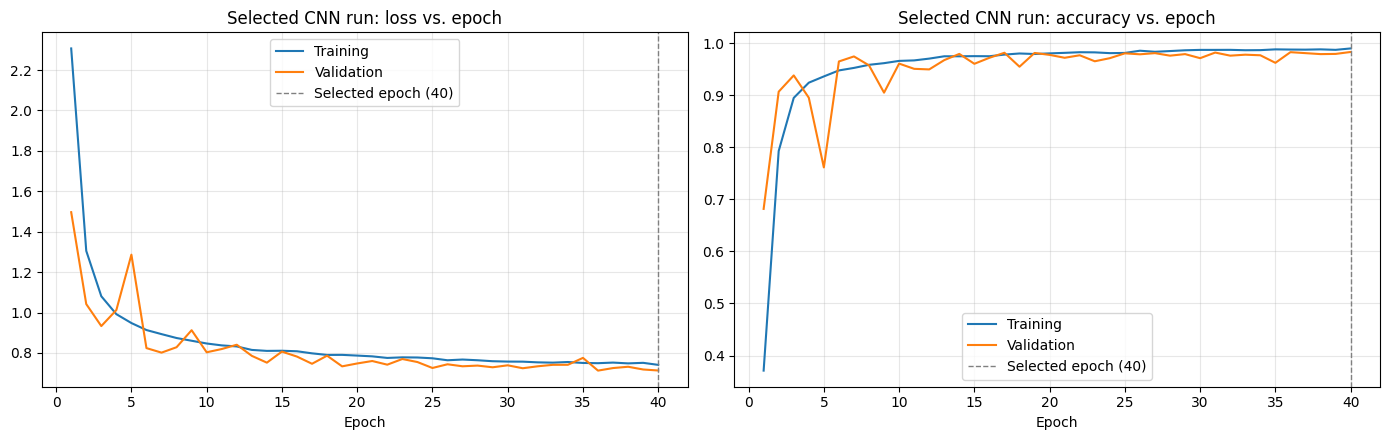

In [43]:
best_es = es_df.sort_values(["val acc", "val loss"], ascending=[False, True]).iloc[0]
BEST_MONITOR = best_es["monitor"]
print(f"Selected: early stopping on {best_es['monitored metric'].lower()} "
      f"(epoch {best_es['selected epoch']}, validation accuracy {best_es['val acc']:.4f})")

cnn_model = AHCDCNN(best_setting["base_filters"], best_setting["dropout"]).to(DEVICE)
cnn_model.load_state_dict(torch.load(os.path.join(CKPT_DIR, f"cnn_es_{BEST_MONITOR}.pt"), map_location=DEVICE))
cnn_test = evaluate(cnn_model, cnn_test_loader)
print(f"CNN test accuracy: {cnn_test['test acc']:.4f} | test macro F1: {cnn_test['test macro F1']:.4f}")

h = es_histories[BEST_MONITOR]
sel = int(best_es["selected epoch"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(h["epoch"], h["train_loss"], label="Training")
axes[0].plot(h["epoch"], h["val_loss"], label="Validation")
axes[0].set_title("Selected CNN run: loss vs. epoch")
axes[1].plot(h["epoch"], h["train_acc"], label="Training")
axes[1].plot(h["epoch"], h["val_acc"], label="Validation")
axes[1].set_title("Selected CNN run: accuracy vs. epoch")
for ax in axes:
    ax.axvline(sel, color="gray", linestyle="--", linewidth=1, label=f"Selected epoch ({sel})")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Discussion.** The three stopping rules behave very differently because the validation curves are noisy in the first epochs: validation accuracy sometimes drops sharply for one epoch (for example to about 0.76 at epoch 5 in the first run) before recovering.

- Stopping on **validation accuracy** was the most affected by this noise. It stopped at epoch 12 and kept epoch 7 (0.9728), which is too early, because the other runs kept improving after that.
- Stopping on **validation loss** ran until epoch 30 and kept epoch 25 (0.9803).
- Stopping on **training accuracy** never triggered. Training accuracy kept rising slowly, so it used all 40 epochs and kept the last one (0.9829).

The training-accuracy run has the highest validation accuracy, so we selected it, and it reaches **0.9845** on the test set. This does not mean that monitoring training accuracy is a good rule in general: it never looks at unseen data, so it cannot detect overfitting. It worked here because the model did not overfit within 40 epochs. The training and validation curves stay close together (0.9897 vs. 0.9829 accuracy at epoch 40), thanks to augmentation, dropout and weight decay. With a larger patience, the two validation-based rules would probably also have trained for longer.

### 1.6 Saving the model and logs

Every training run above wrote its per-epoch log to `logs/`, and every early stopping run saved its checkpoint to `checkpoints/`. Here we copy the selected checkpoint to `checkpoints/cnn_best.pt` and save its configuration and results next to it, then check that the saved file reloads correctly.

In [44]:
shutil.copy(os.path.join(CKPT_DIR, f"cnn_es_{BEST_MONITOR}.pt"), os.path.join(CKPT_DIR, "cnn_best.pt"))
cnn_config = {
    "model": "AHCDCNN", **best_setting, "optimizer": "Adam", "loss": LOSS_NAME, "weight_decay": 1e-4,
    "batch_size": BATCH_SIZE, "early_stopping_monitor": BEST_MONITOR, "patience": PATIENCE,
    "selected_epoch": int(best_es["selected epoch"]), "val_acc": float(best_es["val acc"]),
    "test_acc": float(cnn_test["test acc"]), "train_mean": TRAIN_MEAN, "train_std": TRAIN_STD,
}
with open(os.path.join(CKPT_DIR, "cnn_best.json"), "w") as f:
    json.dump(cnn_config, f, indent=2)

reloaded = AHCDCNN(best_setting["base_filters"], best_setting["dropout"]).to(DEVICE)
reloaded.load_state_dict(torch.load(os.path.join(CKPT_DIR, "cnn_best.pt"), map_location=DEVICE))
print(f"Reloaded checkpoint test accuracy: {evaluate(reloaded, cnn_test_loader)['test acc']:.4f}")
print("Saved logs:", sorted(os.listdir(LOG_DIR)))
print("Saved checkpoints:", sorted(os.listdir(CKPT_DIR)))

Reloaded checkpoint test accuracy: 0.9845
Saved logs: ['cnn_early_stopping_train_acc.csv', 'cnn_early_stopping_val_acc.csv', 'cnn_early_stopping_val_loss.csv', 'cnn_tuning_setting1.csv', 'cnn_tuning_setting2.csv', 'cnn_tuning_setting3.csv', 'cnn_tuning_setting4.csv', 'mlp_milestone2.csv', 'tl_MobileNetV2_extra_layers_lr0.001.csv', 'tl_MobileNetV2_head_only_lr0.001.csv', 'tl_MobileNetV2_last_3_layers_lr0.0001.csv', 'tl_MobileNetV2_last_3_layers_lr0.001.csv', 'tl_ResNet18_extra_layers_lr0.001.csv', 'tl_ResNet18_head_only_lr0.001.csv', 'tl_ResNet18_last_3_layers_lr0.0001.csv', 'tl_ResNet18_last_3_layers_lr0.001.csv', 'tl_VGG19_extra_layers_lr0.001.csv', 'tl_VGG19_head_only_lr0.001.csv', 'tl_VGG19_last_3_layers_lr0.0001.csv', 'tl_VGG19_last_3_layers_lr0.001.csv']
Saved checkpoints: ['best_pretrained.json', 'best_pretrained.pt', 'cnn_best.json', 'cnn_best.pt', 'cnn_es_train_acc.pt', 'cnn_es_val_acc.pt', 'cnn_es_val_loss.pt', 'tl_MobileNetV2_extra_layers_lr0.001.pt', 'tl_MobileNetV2_head_onl

### CNN vs. MLP from Milestone 2

To compare fairly on the same test set, we retrain our shallow MLP from Milestone 2 (two hidden layers, 512 and 256 units) with the settings we selected in Milestone 2: cross-entropy with label smoothing, RMSprop, learning rate 0.0003, weight decay 1e-5, dropout 0.2, batch size 64 and 30 epochs. It uses the same data and the same flattened, normalized input. In Milestone 2 this model reached a test accuracy of 0.7914.

In [45]:
MLP_SETTINGS = {"hidden": [512, 256], "loss": "CE + Label Smoothing", "optimizer": "RMSprop", "lr": 3e-4,
                "weight_decay": 1e-5, "dropout": 0.2, "epochs": 30, "batch_size": 64}


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, num_classes, dropout=0.2):
        super().__init__()
        layers, prev = [], input_dim
        for units in hidden_dims:
            layers += [nn.Linear(prev, units), nn.ReLU(), nn.Dropout(dropout)]
            prev = units
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


mlp_train = torch.utils.data.TensorDataset(*prep.transform(X_train_raw, y_train_raw))
mlp_val = torch.utils.data.TensorDataset(*prep.transform(X_val_raw, y_val_raw))
mlp_test = torch.utils.data.TensorDataset(*prep.transform(X_test_raw, y_test_raw))
mlp_train_loader = DataLoader(mlp_train, batch_size=MLP_SETTINGS["batch_size"], shuffle=True)
mlp_val_loader = DataLoader(mlp_val, batch_size=256)
mlp_test_loader = DataLoader(mlp_test, batch_size=256)

set_seed()
mlp_model = MLP(IMAGE_SIZE * IMAGE_SIZE, MLP_SETTINGS["hidden"], NUM_CLASSES, MLP_SETTINGS["dropout"]).to(DEVICE)
_, mlp_info = fit(mlp_model, mlp_train_loader, mlp_val_loader, MLP_SETTINGS["epochs"], MLP_SETTINGS["lr"],
                  MLP_SETTINGS["weight_decay"], MLP_SETTINGS["optimizer"], MLP_SETTINGS["loss"], log_name="mlp_milestone2")
mlp_test_result = evaluate(mlp_model, mlp_test_loader, MLP_SETTINGS["loss"])

cnn_vs_mlp = pd.DataFrame([
    {"model": "Shallow MLP (Milestone 2)", "trainable params": count_params(mlp_model)[0],
     "val acc": mlp_info["val acc"], **mlp_test_result},
    {"model": "CNN from scratch (Milestone 3)", "trainable params": count_params(cnn_model)[0],
     "val acc": float(best_es["val acc"]), **cnn_test},
])
display(cnn_vs_mlp)
gain = cnn_test["test acc"] - mlp_test_result["test acc"]
print(f"The CNN is {gain * 100:+.2f} percentage points {'better' if gain > 0 else 'worse'} than the MLP on the test set.")

,model,trainable params,val acc,test loss,test acc,test macro F1
0,Shallow MLP (Milestone 2),663324,0.7809,1.2335,0.7967,0.7968
1,CNN from scratch (Milestone 3),819068,0.9829,0.7185,0.9845,0.9845


The CNN is +18.78 percentage points better than the MLP on the test set.


**Discussion.** The CNN improves the test accuracy from 0.7967 to 0.9845 (+18.8 percentage points) with only about 25% more parameters (0.82 million vs. 0.66 million). The MLP treats every pixel as a separate input, so a letter shifted by a few pixels looks completely different to it. The convolution layers reuse the same filters over the whole image, and the pooling layers make the features tolerant to small shifts, which is exactly the kind of variation handwriting has. Augmentation adds to this by showing the CNN slightly rotated, shifted and resized letters.

The retrained MLP gets 0.7967 here instead of the 0.7914 we reported in Milestone 2, because this notebook ran on a GPU instead of a CPU, which slightly changes the random numbers during training.

# Part 2: Transfer Learning

We use three networks pretrained on ImageNet: **VGG19**, **ResNet18** and **MobileNetV2**. They expect 3-channel color images with ImageNet normalization, so we add a small input adapter in front of each network:

1. Resize the 32 × 32 image to 64 × 64 (bilinear). These networks downsample by 32, so a 32 × 32 input would end as a single pixel. With 64 × 64 the last feature map is 2 × 2. We do not use 224 × 224 because it would make training about 12 times slower for very little gain on such small images.
2. Repeat the grayscale channel three times.
3. Normalize with the ImageNet mean and standard deviation (instead of our own training mean), because the pretrained weights were learned with that normalization.

Training images are augmented exactly as in Part 1. All runs use Adam, cross-entropy with label smoothing, batch size 128 and 8 epochs, and keep the epoch with the best validation accuracy.

In [46]:
PRETRAINED_SIZE = 64
TL_EPOCHS = 8
ARCHS = ["VGG19", "ResNet18", "MobileNetV2"]
HEAD_PATH = {"VGG19": ("classifier", 6), "ResNet18": ("fc", None), "MobileNetV2": ("classifier", 1)}


class InputAdapter(nn.Module):
    def __init__(self, size=PRETRAINED_SIZE):
        super().__init__()
        self.size = size
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False)
        return (x.repeat(1, 3, 1, 1) - self.mean) / self.std


class PretrainedNet(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.adapter = InputAdapter()
        self.backbone = backbone

    def forward(self, x):
        return self.backbone(self.adapter(x))


def load_backbone(arch):
    if arch == "VGG19":
        return models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1)
    if arch == "ResNet18":
        return models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if arch == "MobileNetV2":
        return models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    raise ValueError(f"Unknown architecture: {arch}")


def get_head(backbone, arch):
    parent, index = HEAD_PATH[arch]
    module = getattr(backbone, parent)
    return module if index is None else module[index]


def set_head(backbone, arch, head):
    parent, index = HEAD_PATH[arch]
    if index is None:
        setattr(backbone, parent, head)
    else:
        getattr(backbone, parent)[index] = head


def unfreeze_last_layers(model, n=3):
    modules = list(model.named_modules())
    weighted = [i for i, (_, m) in enumerate(modules) if isinstance(m, (nn.Conv2d, nn.Linear))]
    names = []
    for name, m in modules[weighted[-n]:]:
        for p in m.parameters(recurse=False):
            p.requires_grad = True
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            names.append(name)
    return names


def build_pretrained(arch, strategy):
    backbone = load_backbone(arch)
    in_features = get_head(backbone, arch).in_features
    if strategy == "Extra layers":
        head = nn.Sequential(nn.Linear(in_features, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.5),
                             nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, NUM_CLASSES))
    else:
        head = nn.Linear(in_features, NUM_CLASSES)
    set_head(backbone, arch, head)
    model = PretrainedNet(backbone)
    for p in model.parameters():
        p.requires_grad = False
    if strategy == "Last 3 layers":
        unfreeze_last_layers(model, 3)
    else:
        for p in head.parameters():
            p.requires_grad = True
    return model


tl_train_loader, tl_val_loader, tl_test_loader = make_loaders(train_transform)

arch_rows = []
for arch in ARCHS:
    m = build_pretrained(arch, "Last 3 layers")
    head_params = sum(p.numel() for p in get_head(m.backbone, arch).parameters())
    arch_rows.append({"model": arch, "total params": count_params(m)[1], "head only (trainable)": head_params,
                      "last 3 layers (trainable)": count_params(m)[0],
                      "last 3 layers": ", ".join(unfreeze_last_layers(m, 3))})
    del m
display(pd.DataFrame(arch_rows))

,model,total params,head only (trainable),last 3 layers (trainable),last 3 layers
0,VGG19,139684956,114716,119660572,"backbone.classifier.0, backbone.classifier.3, ..."
1,ResNet18,11190876,14364,4735004,"backbone.layer4.1.conv1, backbone.layer4.1.con..."
2,MobileNetV2,2259740,35868,755868,"backbone.features.17.conv.2, backbone.features..."


In [47]:
tl_results = []


def run_transfer(arch, strategy, lr, epochs=TL_EPOCHS):
    set_seed()
    model = build_pretrained(arch, strategy).to(DEVICE)
    trainable, total = count_params(model)
    name = f"tl_{arch}_{strategy.replace(' ', '_').lower()}_lr{lr:g}"
    _, info = fit(model, tl_train_loader, tl_val_loader, epochs, lr, log_name=name)
    path = os.path.join(CKPT_DIR, f"{name}.pt")
    torch.save(model.state_dict(), path)
    result = {"model": arch, "strategy": strategy, "lr": lr, "trainable params": trainable,
              "total params": total, "best epoch": info["selected epoch"], "val acc": info["val acc"],
              "time (s)": info["time (s)"], "checkpoint": path}
    tl_results.append(result)
    print(f"{arch:<12} {strategy:<14} lr={lr:<7g} trainable={trainable:>12,}  "
          f"val acc={info['val acc']:.4f} (epoch {info['selected epoch']})  "
          f"{info['time (s)']:.0f}s")
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result


def test_checkpoint(result):
    model = build_pretrained(result["model"], result["strategy"]).to(DEVICE)
    model.load_state_dict(torch.load(result["checkpoint"], map_location=DEVICE))
    scores = evaluate(model, tl_test_loader)
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return scores

### 2.1 Training only the classification layer

We replace the ImageNet classifier (1000 classes) of each network with a new linear layer with 28 outputs. Everything else is frozen, so only this last layer is trained (learning rate 1e-3).

In [48]:
head_rows = []
for arch in ARCHS:
    result = run_transfer(arch, "Head only", 1e-3)
    head_rows.append({**{k: result[k] for k in ["model", "trainable params", "val acc"]}, **test_checkpoint(result)})
head_df = pd.DataFrame(head_rows)
display(head_df)

VGG19        Head only      lr=0.001   trainable=     114,716  val acc=0.6384 (epoch 7)  98s
ResNet18     Head only      lr=0.001   trainable=      14,364  val acc=0.7619 (epoch 8)  71s
MobileNetV2  Head only      lr=0.001   trainable=      35,868  val acc=0.6778 (epoch 8)  73s


,model,trainable params,val acc,test loss,test acc,test macro F1
0,VGG19,114716,0.6384,1.6576,0.6449,0.6396
1,ResNet18,14364,0.7619,1.3838,0.7634,0.7587
2,MobileNetV2,35868,0.6778,1.6816,0.6836,0.6823


**Discussion.** With only the new output layer trained, the pretrained networks do much worse than our small CNN: 0.64 (VGG19), 0.76 (ResNet18) and 0.68 (MobileNetV2) validation accuracy. The frozen features were learned on ImageNet, which contains color photos of objects, while our images are thin white strokes on a black background that we had to upscale from 32 × 32. These features do not separate the 28 letters well, and a single linear layer on top of them cannot fix that.

### 2.2 Training only the last three layers

Now the backbone stays frozen except for the **last three layers with weights** (the new output layer and the two layers before it), together with the batch normalization layers between them. For VGG19 these are the three fully connected layers, for ResNet18 the last two convolutions of the last residual block and the output layer, and for MobileNetV2 the last two 1 × 1 convolutions and the output layer.

These layers already hold pretrained weights, so a learning rate that is too large can destroy what they learned, while one that is too small may not adapt them enough. We therefore try two learning rates (1e-3 and 1e-4) for each network and keep the one with the higher validation accuracy. Only the selected one is evaluated on the test set.

In [49]:
LAST3_LRS = [1e-3, 1e-4]
last3_runs = [run_transfer(arch, "Last 3 layers", lr) for arch in ARCHS for lr in LAST3_LRS]
last3_df = pd.DataFrame(last3_runs)[["model", "lr", "trainable params", "best epoch", "val acc", "time (s)"]]
print("Learning rate comparison (validation set):")
display(last3_df.pivot(index="model", columns="lr", values="val acc").loc[ARCHS])

last3_rows = []
for arch in ARCHS:
    candidates = [r for r in last3_runs if r["model"] == arch]
    chosen = max(candidates, key=lambda r: r["val acc"])
    last3_rows.append({"model": arch, "selected lr": chosen["lr"], "trainable params": chosen["trainable params"],
                       "val acc": chosen["val acc"], **test_checkpoint(chosen)})
last3_test_df = pd.DataFrame(last3_rows)
display(last3_test_df)

VGG19        Last 3 layers  lr=0.001   trainable= 119,660,572  val acc=0.8058 (epoch 7)  118s
VGG19        Last 3 layers  lr=0.0001  trainable= 119,660,572  val acc=0.8344 (epoch 6)  117s
ResNet18     Last 3 layers  lr=0.001   trainable=   4,735,004  val acc=0.9144 (epoch 8)  72s
ResNet18     Last 3 layers  lr=0.0001  trainable=   4,735,004  val acc=0.9256 (epoch 8)  73s
MobileNetV2  Last 3 layers  lr=0.001   trainable=     755,868  val acc=0.6384 (epoch 7)  73s
MobileNetV2  Last 3 layers  lr=0.0001  trainable=     755,868  val acc=0.7593 (epoch 7)  73s
Learning rate comparison (validation set):


lr,0.0001,0.0010
model,,
VGG19,0.8344,0.8058
ResNet18,0.9256,0.9144
MobileNetV2,0.7593,0.6384


,model,selected lr,trainable params,val acc,test loss,test acc,test macro F1
0,VGG19,0.0001,119660572,0.8344,1.1430,0.8268,0.8252
1,ResNet18,0.0001,4735004,0.9256,0.8977,0.9357,0.9353
2,MobileNetV2,0.0001,755868,0.7593,1.3394,0.7744,0.7761


**Discussion.** Training the last three layers is the best of the three strategies for every network. ResNet18 goes from 0.76 to 0.93 and VGG19 from 0.64 to 0.83 on validation, because the highest layers can now adapt their features to handwriting.

The smaller learning rate (1e-4) was better for all three networks, and the difference is largest for MobileNetV2 (0.7593 vs. 0.6384). These layers start from pretrained weights, and a learning rate of 1e-3 changes them too quickly and destroys part of what they learned. This is why fine-tuning normally uses a smaller learning rate than training a new layer from scratch.

VGG19 trains almost 120 million parameters here but is still clearly behind ResNet18, which trains 4.7 million, so the number of trainable parameters is not what matters most.

### 2.3 Adding more layers on top of the frozen networks

Here we replace the classifier with a deeper head: Linear (512) → BatchNorm → ReLU → Dropout (0.5) → Linear (256) → ReLU → Dropout (0.3) → Linear (28). All pretrained layers are frozen, and only the new layers are trained (learning rate 1e-3).

In [50]:
extra_rows = []
for arch in ARCHS:
    result = run_transfer(arch, "Extra layers", 1e-3)
    extra_rows.append({**{k: result[k] for k in ["model", "trainable params", "val acc"]}, **test_checkpoint(result)})
extra_df = pd.DataFrame(extra_rows)
display(extra_df)

VGG19        Extra layers   lr=0.001   trainable=   2,237,212  val acc=0.6473 (epoch 7)  100s
ResNet18     Extra layers   lr=0.001   trainable=     402,204  val acc=0.8352 (epoch 8)  72s
MobileNetV2  Extra layers   lr=0.001   trainable=     795,420  val acc=0.7325 (epoch 7)  74s


,model,trainable params,val acc,test loss,test acc,test macro F1
0,VGG19,2237212,0.6473,1.5796,0.6545,0.6474
1,ResNet18,402204,0.8352,1.1096,0.8518,0.8510
2,MobileNetV2,795420,0.7325,1.4078,0.7277,0.7269


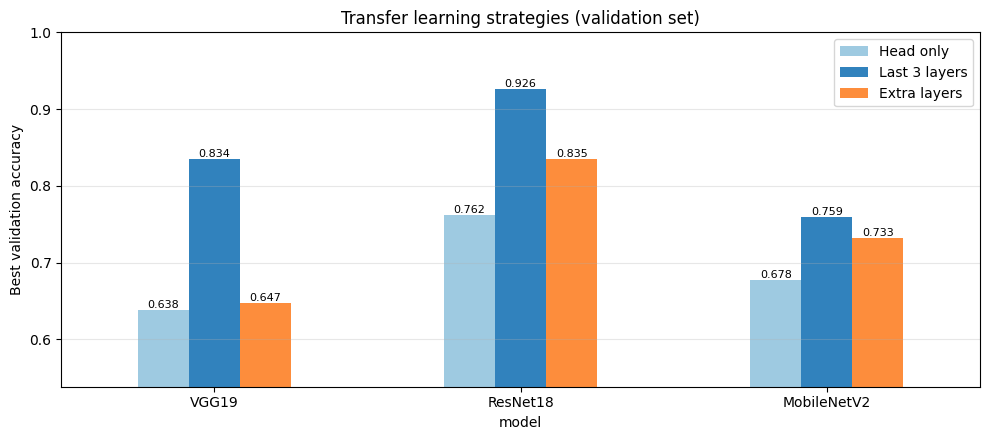

Validation accuracy:


,Head only,Last 3 layers,Extra layers
model,,,
VGG19,0.6384,0.8344,0.6473
ResNet18,0.7619,0.9256,0.8352
MobileNetV2,0.6778,0.7593,0.7325


Test accuracy:


,Head only,Last 3 layers,Extra layers
model,,,
VGG19,0.6449,0.8268,0.6545
ResNet18,0.7634,0.9357,0.8518
MobileNetV2,0.6836,0.7744,0.7277


In [51]:
pivot = pd.DataFrame({
    "Head only": head_df.set_index("model")["val acc"],
    "Last 3 layers": last3_test_df.set_index("model")["val acc"],
    "Extra layers": extra_df.set_index("model")["val acc"],
}).loc[ARCHS]
test_pivot = pd.DataFrame({
    "Head only": head_df.set_index("model")["test acc"],
    "Last 3 layers": last3_test_df.set_index("model")["test acc"],
    "Extra layers": extra_df.set_index("model")["test acc"],
}).loc[ARCHS]
ax = pivot.plot(kind="bar", figsize=(10, 4.5), rot=0, color=["#9ecae1", "#3182bd", "#fd8d3c"])
ax.set_ylabel("Best validation accuracy")
ax.set_ylim(max(0.0, pivot.values.min() - 0.1), 1.0)
ax.set_title("Transfer learning strategies (validation set)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
print("Validation accuracy:")
display(pivot)
print("Test accuracy:")
display(test_pivot)

**Discussion.** Adding a deeper head on top of the frozen network (Section 2.3) helps compared with training only the output layer, especially for ResNet18 (0.76 → 0.84) and MobileNetV2 (0.68 → 0.73). VGG19 barely improves (0.64 → 0.65). It is still clearly worse than unfreezing the last layers. This shows that the bottleneck is the frozen features themselves, not the size of the classifier: more layers on top cannot recover information that the frozen backbone does not extract.

ResNet18 is the best network with all three strategies. A likely reason is the small input: with 64 × 64 images, the last feature map is only 2 × 2. ResNet18 simply averages it (global average pooling), while VGG19's classifier was designed for a 7 × 7 feature map and has to work with a stretched 2 × 2 map.

### 2.4 Saving the best pretrained model

We pick the best configuration from Sections 2.1–2.3 by **validation accuracy** and save it as `checkpoints/best_pretrained.pt`, together with a JSON file that describes how to rebuild it.

In [52]:
best_tl = max(tl_results, key=lambda r: r["val acc"])
BEST_TL_PATH = os.path.join(CKPT_DIR, "best_pretrained.pt")
shutil.copy(best_tl["checkpoint"], BEST_TL_PATH)
best_tl_test = test_checkpoint(best_tl)
best_tl_config = {k: best_tl[k] for k in ["model", "strategy", "lr", "best epoch", "val acc"]}
best_tl_config.update({"input_size": PRETRAINED_SIZE, "test_acc": best_tl_test["test acc"]})
with open(os.path.join(CKPT_DIR, "best_pretrained.json"), "w") as f:
    json.dump(best_tl_config, f, indent=2, default=float)
print(f"Best pretrained model: {best_tl['model']} with '{best_tl['strategy']}' (lr {best_tl['lr']:g})")
print(f"Validation accuracy {best_tl['val acc']:.4f} | test accuracy {best_tl_test['test acc']:.4f}")
print("Saved to", BEST_TL_PATH)

Best pretrained model: ResNet18 with 'Last 3 layers' (lr 0.0001)
Validation accuracy 0.9256 | test accuracy 0.9357
Saved to checkpoints/best_pretrained.pt


### 2.5 The best pretrained model as a feature extractor

We load the saved model, replace its classification head with an identity layer, and use the output of the frozen network as a feature vector for each image (no augmentation). These features are then used to train three classical models:

- **SVM** (RBF kernel) after standardization and PCA to 256 dimensions, with C chosen on the validation set.
- **Random forest** with 300 trees, with the number of features per split chosen on the validation set.
- **Logistic regression** after standardization and PCA, with C chosen on the validation set.

In [53]:
@torch.no_grad()
def extract_features(model, loader):
    model.eval()
    feats, labels = [], []
    for xb, yb in loader:
        feats.append(model(xb.to(DEVICE)).cpu())
        labels.append(yb)
    return torch.cat(feats).numpy(), torch.cat(labels).numpy()


extractor = build_pretrained(best_tl["model"], best_tl["strategy"]).to(DEVICE)
extractor.load_state_dict(torch.load(BEST_TL_PATH, map_location=DEVICE))
set_head(extractor.backbone, best_tl["model"], nn.Identity())

plain_train_loader = DataLoader(AHCDDataset(train_images, train_labels), batch_size=256, shuffle=False,
                                num_workers=NUM_WORKERS)
start = time.time()
F_train, yf_train = extract_features(extractor, plain_train_loader)
F_val, yf_val = extract_features(extractor, tl_val_loader)
F_test, yf_test = extract_features(extractor, tl_test_loader)
print(f"Feature shapes: train {F_train.shape}, val {F_val.shape}, test {F_test.shape} ({time.time() - start:.0f}s)")

Feature shapes: train (10752, 512), val (2688, 512), test (3360, 512) (3s)


In [54]:
candidates = {
    "SVM (RBF)": [("C=1", lambda: make_pipeline(StandardScaler(), PCA(256, random_state=SEED), SVC(C=1))),
                  ("C=10", lambda: make_pipeline(StandardScaler(), PCA(256, random_state=SEED), SVC(C=10)))],
    "Random Forest": [("max_features=sqrt", lambda: RandomForestClassifier(300, max_features="sqrt", n_jobs=-1, random_state=SEED)),
                      ("max_features=log2", lambda: RandomForestClassifier(300, max_features="log2", n_jobs=-1, random_state=SEED))],
    "Logistic Regression": [("C=0.1", lambda: make_pipeline(StandardScaler(), PCA(256, random_state=SEED), LogisticRegression(C=0.1, max_iter=2000))),
                            ("C=1", lambda: make_pipeline(StandardScaler(), PCA(256, random_state=SEED), LogisticRegression(C=1, max_iter=2000)))],
}

fe_rows = []
for name, options in candidates.items():
    trials = []
    for label, make in options:
        start = time.time()
        clf = make().fit(F_train, yf_train)
        trials.append((accuracy_score(yf_val, clf.predict(F_val)), label, clf, time.time() - start))
        print(f"{name:<20} {label:<18} val acc {trials[-1][0]:.4f}  ({trials[-1][3]:.0f}s)")
    val_acc, label, clf, seconds = max(trials, key=lambda t: t[0])
    test_pred = clf.predict(F_test)
    fe_rows.append({"classifier": name, "selected setting": label, "val acc": val_acc,
                    "test acc": accuracy_score(yf_test, test_pred),
                    "test macro F1": f1_score(yf_test, test_pred, average="macro"), "fit time (s)": seconds})

fe_df = pd.DataFrame(fe_rows)
display(fe_df)

SVM (RBF)            C=1                val acc 0.9453  (11s)
SVM (RBF)            C=10               val acc 0.9446  (10s)
Random Forest        max_features=sqrt  val acc 0.9267  (71s)
Random Forest        max_features=log2  val acc 0.9200  (30s)
Logistic Regression  C=0.1              val acc 0.9382  (9s)
Logistic Regression  C=1                val acc 0.9282  (4s)


,classifier,selected setting,val acc,test acc,test macro F1,fit time (s)
0,SVM (RBF),C=1,0.9453,0.9482,0.9483,11.2502
1,Random Forest,max_features=sqrt,0.9267,0.9318,0.9317,70.9462
2,Logistic Regression,C=0.1,0.9382,0.9429,0.9430,8.5228


**Discussion.** The best saved model is ResNet18 with its last three layers trained, so each image is described by the 512 values after its global average pooling. All three classical models work well on these features, and the RBF SVM is the best (0.9453 validation, **0.9482 test**). It even beats the ResNet18 network the features came from (0.9357 test). The SVM can draw non-linear boundaries between the classes, while the network ends in a single linear layer that was only trained for 8 epochs.

The random forest is both the weakest (0.9318 test) and the slowest (71 seconds). Its splits use one feature at a time, which is less efficient for 512 continuous features than the SVM's kernel. The two values of C gave almost the same accuracy for the SVM, so the simpler C = 1 was kept.

## Final comparison on the test set

,model,test acc,test macro F1
0,Shallow MLP (Milestone 2),0.7967,0.7968
1,CNN from scratch (early stopping),0.9845,0.9845
2,ResNet18 (last 3 layers),0.9357,0.9353
3,SVM (RBF) on ResNet18 features,0.9482,0.9483


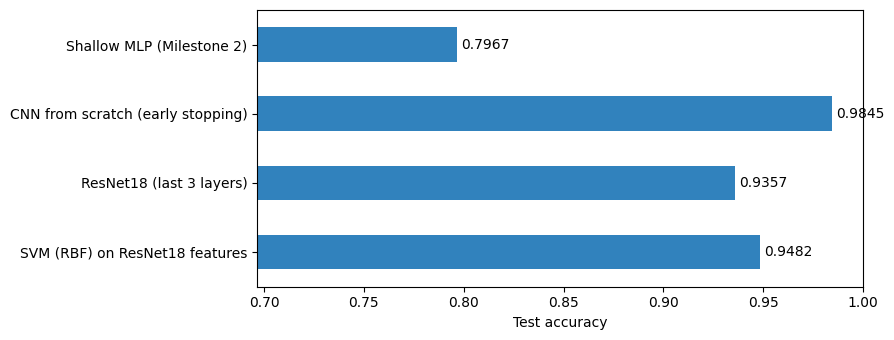

In [55]:
best_fe = fe_df.sort_values("val acc", ascending=False).iloc[0]
final = pd.DataFrame([
    {"model": "Shallow MLP (Milestone 2)", "test acc": mlp_test_result["test acc"], "test macro F1": mlp_test_result["test macro F1"]},
    {"model": "CNN from scratch (early stopping)", "test acc": cnn_test["test acc"], "test macro F1": cnn_test["test macro F1"]},
    {"model": f"{best_tl['model']} ({best_tl['strategy'].lower()})", "test acc": best_tl_test["test acc"], "test macro F1": best_tl_test["test macro F1"]},
    {"model": f"{best_fe['classifier']} on {best_tl['model']} features", "test acc": best_fe["test acc"], "test macro F1": best_fe["test macro F1"]},
])
display(final)

ax = final.plot(x="model", y="test acc", kind="barh", legend=False, figsize=(9, 3.5), color="#3182bd")
ax.set_xlim(max(0.0, final["test acc"].min() - 0.1), 1.0)
ax.set_xlabel("Test accuracy")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], fmt="%.4f", padding=3)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Conclusion

Our CNN trained from scratch is the best model in this milestone, with **98.45% test accuracy** (macro F1 0.9845), compared with 79.67% for the MLP from Milestone 2. Transfer learning from ImageNet did not beat it. The best pretrained setup (ResNet18 with the last three layers trained) reached 93.57%, and an SVM on its features reached 94.82%.

We think the main reasons are:

- **Domain gap:** ImageNet photos look very different from small grayscale handwritten letters, so the pretrained features are less useful, and frozen layers cannot adapt to the new task.
- **Image size:** the pretrained networks were designed for 224 × 224 images, and we gave them 64 × 64 images upscaled from 32 × 32.
- **Enough data for a small CNN:** 10,752 training images are enough to train a CNN with 0.8 million parameters from scratch, so we do not need to borrow features from another task.
- **Training budget:** the pretrained networks were trained for 8 epochs, while the selected CNN trained for 40.

The CNN from scratch remains our best model so far. It is saved in `checkpoints/cnn_best.pt`, with its settings in `checkpoints/cnn_best.json`.

In [56]:
small = [os.path.join(CKPT_DIR, f) for f in ["cnn_best.pt", "cnn_best.json", "best_pretrained.json"]]
os.makedirs("milestone3_outputs", exist_ok=True)
shutil.copytree(LOG_DIR, os.path.join("milestone3_outputs", "logs"), dirs_exist_ok=True)
for path in small:
    shutil.copy(path, "milestone3_outputs")
shutil.make_archive("milestone3_outputs", "zip", "milestone3_outputs")
print("Created milestone3_outputs.zip with the logs, the selected CNN checkpoint and both configuration files.")
print(f"The best pretrained checkpoint is {BEST_TL_PATH} ({os.path.getsize(BEST_TL_PATH) / 1e6:.0f} MB).")

Created milestone3_outputs.zip with the logs, the selected CNN checkpoint and both configuration files.
The best pretrained checkpoint is checkpoints/best_pretrained.pt (45 MB).
